Goals of the notebook:

- Cluster the Astro-Epen cells
- Save out labelmat

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import yaml 
from pathlib import Path 

import numpy as np
import pandas as pd
import scanpy as sc
from dotenv import dotenv_values

from hm3d_utils.clustering import run_decomposition 
from hm3d_utils.plotting import zoom_umap

### Data loading and preprocessing

In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])
CLUSTERING_DIR = DATADIR / "5_clustering"
MODELDIR = CLUSTERING_DIR / 'all_control'
DATASETS_DIR = MODELDIR / "datasets"


In [4]:
PARAMS_FILE = Path("resources", "clustering_params.yaml")


In [5]:
CELL_TYPE = "Astro" 

if CELL_TYPE == "Neuro":
    adata_fp = DATASETS_DIR / 'neuronal_raw_embed_propagated.h5ad'
else:
    adata_fp = DATASETS_DIR / 'glial_raw_embed_propagated.h5ad'

In [6]:

with open(PARAMS_FILE, "r") as fp:
            parameters = yaml.safe_load(fp)

parameters

{'loop': {'initial_solution_key': 'L1', 'max_levels': 10},
 'neighbors': {'n_neighbors': 15, 'use_rep': 'X_embed'},
 'leiden': {'n_iterations': 5, 'n_jobs': 20, 'n_seeds': 100, 'resolution': []},
 'consensus': {'random_state': 0},
 'pruning': {'max_stratum_size': 10000,
  'min_stratum_size': 10,
  'min_cluster_size': 100,
  'min_marker_genes': 30,
  'symmetric_intermediate_resolution': True,
  'symmetric_highest_resolution': False,
  'min_pct_expression': 0.1,
  'min_specificity': 0.2,
  'min_strata': 2,
  'nn_checks': 2,
  'random_state': 0,
  'significance_threshold': 0.001,
  'strata_key': 'Sample',
  'use_rep': 'X_embed'},
 'masking': {'enabled': False,
  'min_nn_agreement': 0.5,
  'n_neighbors': 40,
  'use_rep': 'X_embed'}}

In [ ]:
adata = sc.read_h5ad(adata_fp, backed="r")
if CELL_TYPE == "Neuro":
    load_mask = adata.obs.IsControl
else:
    load_mask = (adata.obs["major_features_propagated"].str.contains(CELL_TYPE)) & (adata.obs.IsControl)

adata = adata[load_mask].to_memory()

adata.obs["L1"] = adata.obs.major_features_propagated.copy()
# Remove excluded genes
adata = adata[:, ~adata.var.IsHvgExcludedGene]

sc.pp.normalize_total(adata, target_sum=10_000)

adata

### Decomposing L1

In [9]:
for res in [0.15,]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = parameters["loop"]["initial_solution_key"],
        max_levels = 1,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"]
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L2_new_{res}"] = labelmat


0 vs 1 passed with 120 vs 264 markers
1 vs 4 passed with 823 vs 615 markers
2 vs 4 passed with 1592 vs 446 markers
0 vs 4 passed with 804 vs 1332 markers
3 or 4 merged due to insufficient cluster size 62/12107.
	>>4 and 3 merged to make 4_3
1 vs 4_3 passed with 830 vs 618 markers
2 vs 4_3 passed with 1587 vs 445 markers
0 vs 4_3 passed with 802 vs 1323 markers
0 vs 2 passed with 735 vs 3167 markers
0 or 5 merged due to insufficient cluster size 84538/58.
	>>5 and 0 merged to make 5_0
1 vs 5_0 passed with 264 vs 120 markers
4_3 vs 5_0 passed with 1324 vs 801 markers
2 vs 5_0 passed with 3168 vs 735 markers
Step finished with  0.00% of obs locked and 4 clusters.                                                                                           


In [10]:
final_l2_col = "L2_new_0.15"

Unfortunately, it was not possible to find a clustering resolution that would result in the same split as the ABC has. 

Hence, we hardcoded the astrocyte clusters together for L2.

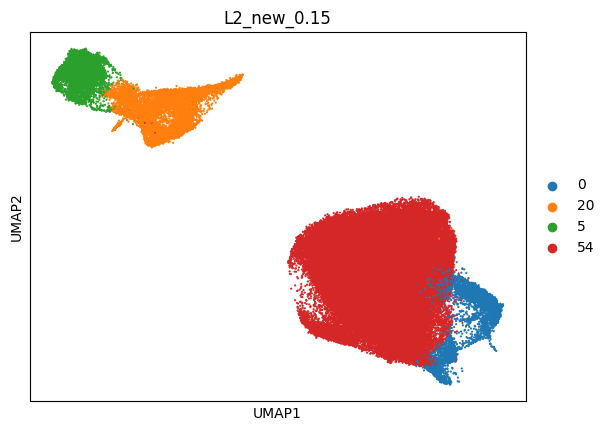

In [11]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l2_col], ncols=1, include_background=False, clip_pct=0.001, s=10)

In [12]:
adata.obs["L2_new_0.15_manual"] = adata.obs["L2_new_0.15"].copy() 
adata.obs.loc[adata.obs["L2_new_0.15"] == "0", "L2_new_0.15_manual"] = "54"

In [13]:
final_l2_col = "L2_new_0.15_manual"

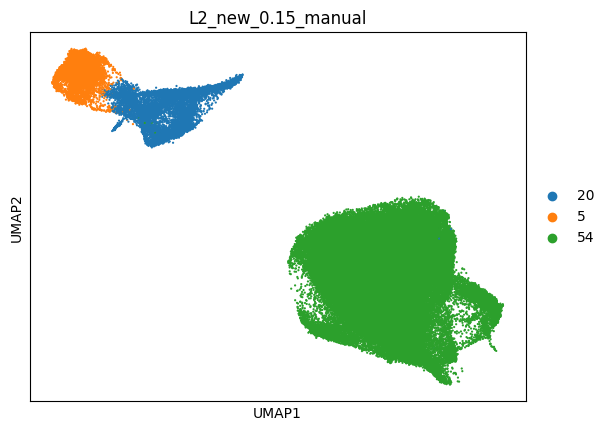

In [15]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l2_col], ncols=1, include_background=False, clip_pct=0.001, s=10)

### Decomposing level 2

Unfortunately, running the same parameters as to get a meaningful split in astrocytes will overcluster ependymal cells/tanycytes.

Hence, we combined two clusterings to get a split approximately matching ABC in terms of resolution.

In [17]:

for res in [0.075,0.16]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l2_col,
        max_levels = 10,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = parameters["pruning"]["symmetric_intermediate_resolution"],
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=1 # start at level idx 1 as you have decomposed the 0th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L3_new_{res}"] = labelmat


0 or 1 merged due to insufficient cluster size 6113/35.
	>>1 and 0 merged to make 1_0
0 vs 1 passed with 157 vs 162 markers
0 vs 3 passed with 286 vs 284 markers
0 vs 1 FAILED with 20 vs 31 markers
	>>1 and 0 merged to make 1_0
3 vs 1_0 passed with 277 vs 281 markers
2 or 1_0 merged due to insufficient cluster size 62/7909.
	>>1_0 and 2 merged to make 1_0_2
3 vs 1_0_2 passed with 273 vs 281 markers
Step finished with  5.65% of obs locked and 5 clusters.                                                                                           
0 vs 1 passed with 76 vs 254 markers
0 or 2 merged due to insufficient cluster size 4121/62.
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 252 vs 75 markers
0 vs 1 passed with 243 vs 361 markers
Step finished with  88.82% of obs locked and 7 clusters.                                                                                           
0 or 1 merged due to insufficient cluster size 4121/62.
	>>1 and 0 merged to make 1_0
0 vs 1 FAILED wit

In [18]:
adata.obs["L3_new_manual"] = adata.obs["L3_new_0.075"].astype(str).copy() 
adata.obs.loc[adata.obs[final_l2_col]=="54", "L3_new_manual"] = adata.obs.loc[adata.obs[final_l2_col]=="54", "L3_new_0.16"].astype(str)

... storing 'L3_new_manual' as categorical


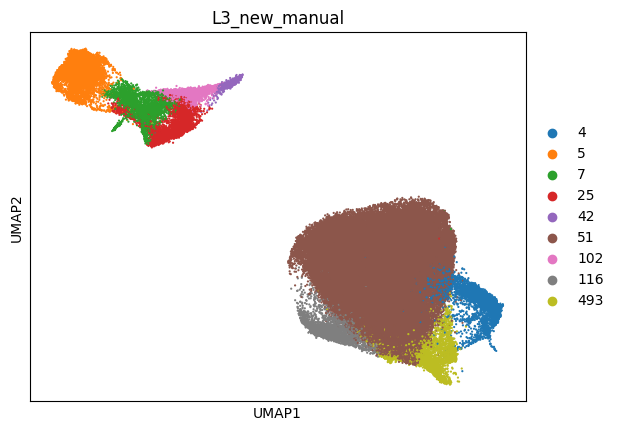

In [19]:
final_l3_col = "L3_new_manual"
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), color=[final_l3_col], ncols=1, include_background=False, clip_pct=0.001, s=10)

### Decomposing L3 

To decompose the previous level into L4, we allow for asymmetric marker gene calculations during pruning.

In [20]:
symmetric = parameters["pruning"]["symmetric_highest_resolution"]

for res in [0.13,]: 

    labelmat = run_decomposition(
        adata,
        use_rep = parameters["neighbors"]["use_rep"],
        init_key = final_l3_col,
        max_levels = 20,
        n_neighbors = parameters["neighbors"]["n_neighbors"],
        resolutions = [res],
        n_seeds = parameters["leiden"]["n_seeds"],
        n_iterations = parameters["leiden"]["n_iterations"],
        n_jobs = parameters["leiden"]["n_jobs"],
        strata_key = parameters["pruning"]["strata_key"],
        nn_checks = parameters["pruning"]["nn_checks"],
        min_cluster_size = parameters["pruning"]["min_cluster_size"],
        min_stratum_size = parameters["pruning"]["min_stratum_size"],
        max_stratum_size = parameters["pruning"]["max_stratum_size"],
        min_strata = parameters["pruning"]["min_strata"],
        min_pct_expression = parameters["pruning"]["min_pct_expression"],
        min_specificity = parameters["pruning"]["min_specificity"],
        significance_threshold = parameters["pruning"]["significance_threshold"],
        min_marker_genes = parameters["pruning"]["min_marker_genes"],
        symmetric = symmetric,
        masking_enabled = parameters["masking"]["enabled"],
        min_nn_agreement = parameters["masking"]["min_nn_agreement"],
        random_state = parameters["pruning"]["random_state"],
        level=11 # start at level idx 11 as you have decomposed up to 10th level before
    )

    labelmat = pd.Series(labelmat[:, -1], index=adata.obs.index).replace('-1', pd.NA).astype("category")

    adata.obs[f"L4_new_{res}_asym"] = labelmat


0 vs 1 passed with 430 markers
1 vs 2 passed with 42 markers
0 vs 2 FAILED with 12 markers
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 438 markers
0 or 1 merged due to insufficient cluster size 70/2605.
	>>1 and 0 merged to make 1_0
0 vs 1 passed with 162 markers
0 or 2 merged due to insufficient cluster size 3494/62.
	>>2 and 0 merged to make 2_0
1 vs 2_0 passed with 160 markers
0 vs 1 passed with 517 markers
0 and 1 merged due to insufficient valid overlapping strata.
	>>1 and 0 merged to make 1_0
2 vs 1_0 passed with 63 markers
0 vs 2 passed with 140 markers
0 vs 1 passed with 1495 markers
1 vs 2 passed with 296 markers
2 or 3 merged due to insufficient cluster size 891/35.
	>>3 and 2 merged to make 3_2
0 vs 3_2 passed with 142 markers
1 vs 3_2 passed with 294 markers
Step finished with  79.83% of obs locked and 15 clusters.                                                                                           
0 or 1 merged due to insufficient cluster size 891/35.
	>>1 an

In [21]:
final_l4_col = "L4_new_0.13_asym"

... storing 'L3_new_manual' as categorical


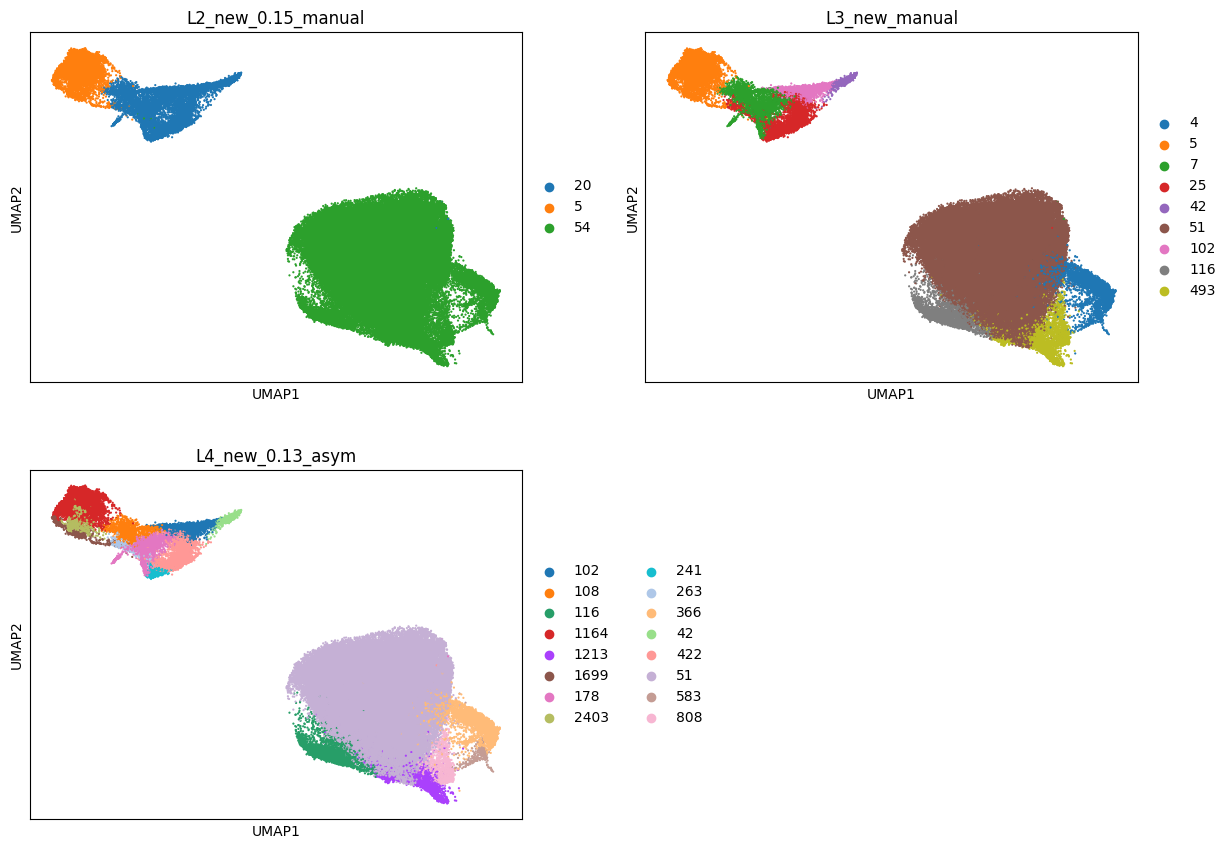

In [22]:
zoom_umap(adata, interest_mask = np.ones(adata.n_obs, dtype=bool), 
    color=[final_l2_col,final_l3_col, final_l4_col,], 
    ncols=2, include_background=False, clip_pct=0.001, s=10)

### Let's save the labelmat

In [23]:
final_labelmat = adata.obs.loc[:, [final_l2_col, final_l3_col, final_l4_col]]
final_labelmat.columns=["L2", "L3", "L4"]
final_labelmat.head()

,L2,L3,L4
SC1-01_SAMN18754353_AAACCCAGTGAGATTA,54,51,51
SC1-01_SAMN18754353_AAACGAACATCCGTGG,54,51,51
SC1-01_SAMN18754353_AAACGAATCAGAGTGG,54,493,808
SC1-01_SAMN18754353_AAACGCTCATGTGGTT,54,51,51
SC1-01_SAMN18754353_AAAGAACTCATTTGCT,20,7,178


In [ ]:
#final_labelmat.to_csv(CLUSTERING_DIR / "astro_epen_labelmat.csv")